Shape: (244, 7)

Info:
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 17.3 KB
None


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Missing values per column:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Duplicate row count: 1


,total_bill,tip,sex,smoker,day,time,size,tip_pct
183,23.17,6.50,Male,Yes,Sun,Dinner,4,28.053517
181,23.33,5.65,Male,Yes,Sun,Dinner,2,24.217745
185,20.69,5.00,Male,No,Sun,Dinner,5,24.166264
214,28.17,6.50,Female,Yes,Sat,Dinner,3,23.074192
46,22.23,5.00,Male,No,Sun,Dinner,2,22.492128
239,29.03,5.92,Male,No,Sat,Dinner,3,20.392697
211,25.89,5.16,Male,Yes,Sat,Dinner,4,19.930475
28,21.70,4.30,Male,No,Sat,Dinner,2,19.815668
106,20.49,4.06,Male,Yes,Sat,Dinner,2,19.814544
73,25.28,5.00,Female,Yes,Sat,Dinner,2,19.778481


,transactions,avg_bill,median_bill,total_tip,avg_tip_pct
day,,,,,
Sun,76,21.41,19.63,247.39,16.69
Sat,87,20.44,18.24,260.40,15.32
Thur,61,17.76,16.40,169.83,16.14
Fri,19,17.15,15.38,51.96,16.99


Correlation Matrix:
             total_bill    tip   size
total_bill       1.000  0.675  0.598
tip              0.675  1.000  0.488
size             0.598  0.488  1.000


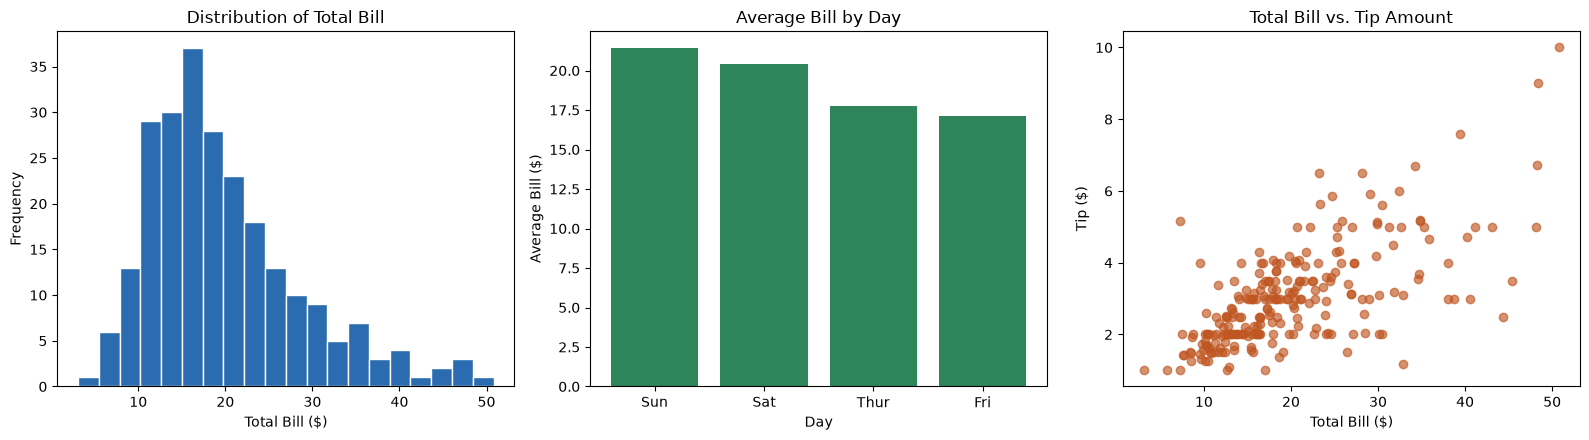

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Optional: load a public CSV directly in Google Colab
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv'
df = pd.read_csv(url)

print('Shape:', df.shape)
print('\nInfo:')
print(df.info())
display(df.head())
# 1. Inspect missing values & exact duplicate rows
print('Missing values per column:\n', df.isna().sum())
print('\nDuplicate row count:', df.duplicated().sum())

# 2. Remove exact duplicates
df_clean = df.drop_duplicates().copy()

# 3. Handle missing values (example strategy)
# - Drop rows if critical target/key columns are missing
# - Impute numeric columns with median (robust to outliers)
# - Impute categorical columns with mode or 'Unknown'
num_cols = df_clean.select_dtypes(include=np.number).columns
cat_cols = df_clean.select_dtypes(exclude=np.number).columns

for col in num_cols:
  if df_clean[col].isna().any():
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in cat_cols:
  if df_clean[col].isna().any():
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Standardize text formatting where helpful
for col in cat_cols:
  df_clean[col] = df_clean[col].astype(str).str.strip()
# Derived metric example
df_clean['tip_pct'] = (df_clean['tip'] / df_clean['total_bill']) * 100

# Filtering & sorting example: high-bill dinner tables sorted by tip %
high_bills = df_clean[
    (df_clean['time'] == 'Dinner') & (df_clean['total_bill'] >= 20)
].sort_values(by='tip_pct', ascending=False)

display(high_bills.head(10))

# Grouping & aggregating across categories
summary_by_day = (
    df_clean.groupby('day', observed=False)
    .agg(
        transactions=('total_bill', 'count'),
        avg_bill=('total_bill', 'mean'),
        median_bill=('total_bill', 'median'),
        total_tip=('tip', 'sum'),
        avg_tip_pct=('tip_pct', 'mean'),
    )
    .round(2)
    .sort_values(by='avg_bill', ascending=False)
)

display(summary_by_day)
# Numerical correlation matrix
corr_matrix = df_clean[num_cols].corr(numeric_only=True)
print('Correlation Matrix:\n', corr_matrix.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Chart 1: Distribution of a key numerical variable
axes[0].hist(
    df_clean['total_bill'], bins=20, color='#2b6cb0', edgecolor='white'
)
axes[0].set_title('Distribution of Total Bill')
axes[0].set_xlabel('Total Bill ($)')
axes[0].set_ylabel('Frequency')

# Chart 2: Group comparison (bar chart of mean values)
axes[1].bar(
    summary_by_day.index.astype(str),
    summary_by_day['avg_bill'],
    color='#2f855a',
)
axes[1].set_title('Average Bill by Day')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Average Bill ($)')

# Chart 3: Relationship between two continuous variables
axes[2].scatter(
    df_clean['total_bill'], df_clean['tip'], alpha=0.65, color='#c05621'
)
axes[2].set_title('Total Bill vs. Tip Amount')
axes[2].set_xlabel('Total Bill ($)')
axes[2].set_ylabel('Tip ($)')

plt.tight_layout()
plt.show()